# 5장 실습. 라우팅·신뢰도 게이팅·캐스케이드

판단 결과를 어디로 보낼지 정하는 레시피 넷을 만든다.

| 절 | 레시피 | 데이터 |
|---|---|---|
| 5.1 | 라우팅 — 요청 하나를 담당 데스크로 보낸다 | topic (뉴스 제목 → 7개 데스크) |
| 5.2 | 신뢰도 게이트 — 자동 처리·표시·사람 셋으로 나눈다 | topic, positive |
| 5.3 | 임계값을 데이터로 정하고, 새 데이터에서도 맞는지 본다 | topic, positive |
| 5.4 | 행동의 위험에 따라 임계값을 다르게 둔다 | 한국어 고객 메시지 6개 |
| 5.5 | 캐스케이드 — 확신이 낮은 것만 다른 쪽으로 넘긴다 | topic |
| 5.6 | 투기적 팬아웃 — 나중에 필요할지 모를 질문까지 한 번에 묻는다 | 한국어 문의 |

5.5 의 폴백은 셋이다. 사람, TF-IDF 기준선(노트북 안에서 1분 남짓 학습), 그리고 사내 GPU 의 로컬 LLM 이다. 로컬 LLM 은 이 노트북이 transformers 로 직접 올린다.

8장의 `data/eval_v1.jsonl` 이 있어야 한다. Jev 에 약 410건(0.02달러 안팎)을 보낸다.

In [1]:
import os, json, time, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import koreanize_matplotlib  # noqa: F401
from dotenv import load_dotenv
from requests.adapters import HTTPAdapter, Retry

load_dotenv()
DATA, OUT = Path("data"), Path("out")
OUT.mkdir(exist_ok=True)
TASKS = ["topic", "entails", "positive", "similarity"]
COLOR = {"topic": "#2a78d6", "entails": "#eb6834", "positive": "#1baf7a", "similarity": "#eda100"}
pd.set_option("display.precision", 3)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
read_jsonl = lambda p: [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

assert (DATA / "eval_v1.jsonl").exists(), "평가셋이 없다. nb00_setup → nb08_evaluation 을 먼저 실행한다"

JEV_URL = os.getenv("JEV_URL", "https://api.typesafe.ai")
http = requests.Session()
http.mount(JEV_URL, HTTPAdapter(max_retries=Retry(total=4, backoff_factor=0.5, status_forcelist=[408, 429, 500, 502, 503, 504])))

def ask(state, questions, model="jev-latest"):
    r = http.post(f"{JEV_URL}/v1/systemone", timeout=60, headers={"Authorization": f"Bearer {os.environ['TYPESAFE_API_KEY']}"},
                  json={"model": model, "state": state, "questions": questions})
    r.raise_for_status()
    return r.json() | {"_latency_s": r.elapsed.total_seconds()}

choice = lambda instructions, criteria: {"type": "choice", "instructions": instructions, "criteria": criteria}
score = lambda instructions, levels: {"type": "score", "instructions": instructions, "criteria": levels}
noul = lambda instructions, true="", false="": {"type": "noul", "instructions": instructions} | ({"criteria": {"true": true, "false": false}} if true else {})

def probs_of(answer):
    return answer.get("probabilities") or {"true": answer["noul"], "false": 1 - answer["noul"]}

def judge(item, resp):
    (task, q), = item["questions"].items()
    a = resp["answers"][task]
    pr = {str(k): float(v) for k, v in probs_of(a).items()}
    best = max(pr, key=pr.get)
    pred = {"noul": lambda: pr["true"] >= 0.5, "choice": lambda: best, "score": lambda: int(best)}[q["type"]]()
    return {"id": item["id"], "task": item["task"], "qtype": q["type"], "gold": item["gold"], "model": resp["model"],
            "pred": pred, "probs": pr, "conf": pr[best], "conf_field": a.get("confidence"), "correct": bool(pred == item["gold"]),
            "input_tokens": resp["usage"]["input_tokens"], "latency_s": resp["_latency_s"]}

def run(items, engine=lambda it: ask(it["state"], it["questions"]), workers=4):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(lambda it: judge(it, engine(it)), items))

arrays = lambda recs: (np.array([r["conf"] for r in recs]), np.array([r["correct"] for r in recs], float))

def ece(conf, ok, bins=15):
    idx = np.clip(np.searchsorted(np.linspace(0, 1, bins + 1), conf, side="left") - 1, 0, bins - 1)
    return float(sum(abs(conf[idx == i].mean() - ok[idx == i].mean()) * (idx == i).sum() for i in np.unique(idx)) / len(conf))

items = read_jsonl(DATA / "eval_v1.jsonl")
by = {t: [i for i in items if i["task"] == t] for t in TASKS}
jev = {t: run(by[t]) for t in ["topic", "positive"]}
pd.DataFrame({t: {"n": len(r), "정확도": arrays(r)[1].mean()} for t, r in jev.items()}).T

,n,정확도
topic,200.0,0.80
positive,200.0,0.85


## 5.1 라우팅 혼동 행렬 분석

라우터를 고칠 때 먼저 볼 것은 정확도 하나가 아니라 혼동 행렬이다. 어느 데스크로 갈 글이 어디로 잘못 가는지 보여 준다.

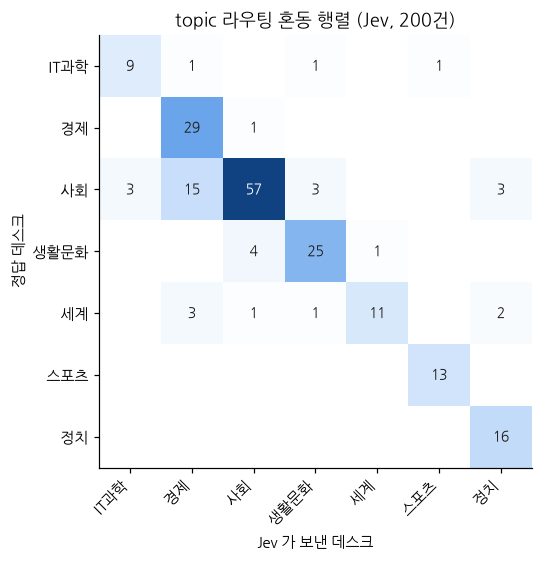

가장 많이 헷갈린 쌍: [('사회', '경제', 15), ('생활문화', '사회', 4), ('사회', 'IT과학', 3), ('사회', '생활문화', 3), ('사회', '정치', 3)]


In [2]:
from matplotlib.colors import LinearSegmentedColormap

desks = list(by["topic"][0]["questions"]["topic"]["criteria"])
M = pd.crosstab(pd.Categorical([r["gold"] for r in jev["topic"]], desks), pd.Categorical([r["pred"] for r in jev["topic"]], desks),
                dropna=False).to_numpy()
fig, ax = plt.subplots(figsize=(6.4, 5.2), dpi=110)
ax.imshow(M, cmap=LinearSegmentedColormap.from_list("b", ["#ffffff", "#cde2fb", "#6da7ec", "#2a78d6", "#104281"]))
for i, j in np.argwhere(M):
    ax.text(j, i, M[i, j], ha="center", va="center", fontsize=9, color=["#1c1c1a", "white"][int(M[i, j] > M.max() * 0.55)])
ax.set_xticks(range(len(desks)), desks, rotation=45, ha="right"); ax.set_yticks(range(len(desks)), desks)
ax.set_xlabel("Jev 가 보낸 데스크"); ax.set_ylabel("정답 데스크"); ax.set_title("topic 라우팅 혼동 행렬 (Jev, 200건)", fontsize=12)
fig.tight_layout(); fig.savefig(OUT / "nb05_confusion.png", bbox_inches="tight"); plt.show()

off = sorted([(desks[i], desks[j], int(M[i, j])) for i, j in np.argwhere(M) if i != j], key=lambda x: -x[2])
print("가장 많이 헷갈린 쌍:", off[:5])

In [3]:
# 잘못 보낸 것 가운데 확신이 높았던 것과 낮았던 것
title = {i["id"]: i["state"] for i in by["topic"]}
wrong = sorted([r for r in jev["topic"] if not r["correct"]], key=lambda r: -r["conf"])
pd.DataFrame([{"확신": r["conf"], "정답": r["gold"], "보낸 곳": r["pred"], "제목": title[r["id"]]} for r in wrong[:4] + wrong[-3:]])

,확신,정답,보낸 곳,제목
0,1.00,사회,경제,구본성 아워홈 부회장 해외사업 강화로 시너지 창출
1,0.99,사회,경제,게시판 예보 금융안정 연구자료 웹페이지 개설
2,0.99,사회,경제,아주경제신문 신임 사장에 김영모 전 한국신문협회 광고협의회장
3,0.99,세계,경제,中완다그룹 美진출작 시카고 완다 비스타 초고가 분양 개시
4,0.46,사회,경제,코로나 극복 노사정 대화 막판 조율…이르면 내일 합의 발표종합
5,0.46,세계,생활문화,싱가포르 세계 미식가 대회 개막
6,0.37,사회,생활문화,감염병 보도준칙 설명하는 권태훈 위원장


## 5.2 3구간 신뢰도 게이트

TypeSafe 문서의 예시 구간을 쓴다. 0.9 이상은 자동 처리, 0.5~0.9 는 처리하되 표시, 0.5 미만은 사람에게 보낸다. 확신으로는 최대 확률을 쓰고, 비교를 위해 응답의 `confidence` 필드로 나눈 결과도 낸다. noul 에는 `confidence` 필드가 없으므로 positive 는 최대 확률로만 나눈다.

In [4]:
BANDS = ["사람 (<0.5)", "표시 (0.5~0.9)", "자동 (≥0.9)"]

def bands(recs, key):
    df = pd.DataFrame(recs)
    out = df.groupby(pd.cut(df[key], [-1, 0.5, 0.9, 1.01], right=False, labels=BANDS), observed=False)["correct"].agg(정확도="mean", 건수="size")
    return out.assign(비율=out["건수"] / len(df))[["비율", "정확도", "건수"]].iloc[::-1]

COMBOS = [("topic", "conf", "최대 확률"), ("topic", "conf_field", "confidence 필드"), ("positive", "conf", "최대 확률")]
pd.concat({(t, label): bands(jev[t], key) for t, key, label in COMBOS}, names=["과제", "기준", "구간"])

비율    정확도   건수
과제       기준            구간                             
topic    최대 확률         자동 (≥0.9)     0.690  0.906  138
                       표시 (0.5~0.9)  0.285  0.579   57
                       사람 (<0.5)     0.025  0.400    5
         confidence 필드 자동 (≥0.9)     0.660  0.924  132
                       표시 (0.5~0.9)  0.295  0.576   59
                       사람 (<0.5)     0.045  0.444    9
positive 최대 확률         자동 (≥0.9)     0.425  1.000   85
                       표시 (0.5~0.9)  0.575  0.739  115
                       사람 (<0.5)     0.000    NaN    0

## 5.3 임계값 선정과 홀드아웃 검증

「오류율 5% 이하로 자동 처리」를 목표로 임계값을 정한다. 200개를 반씩 나눠 앞 절반에서 목표를 지키는 가장 낮은 임계값을 고르고, 뒤 절반에서 실제 오류율을 잰다. 나누는 방법을 500번 바꿔 반복하면 100개로 고른 임계값이 새 데이터에서 얼마나 빗나가는지 분포로 보인다.

In [5]:
def pick_threshold(conf, ok, risk=0.05):
    ts = np.unique(conf)
    err = np.array([1 - ok[conf >= t].mean() for t in ts])
    return np.append(ts[err <= risk], np.nan)[0]          # 목표를 지키는 임계값이 없으면 nan

def transfer(recs, risk=0.05, n=500, seed=0):
    conf, ok = arrays(recs)
    rng = np.random.default_rng(seed)
    perms = [rng.permutation(len(conf)) for _ in range(n)]
    rows = [{"t": (t := pick_threshold(conf[p[:100]], ok[p[:100]], risk)),
             "test_cov": (conf[p[100:]] >= t).mean(), "test_err": pd.Series(1 - ok[p[100:]][conf[p[100:]] >= t]).mean()} for p in perms]
    return pd.DataFrame(rows).dropna(subset=["t"])

tr = {t: transfer(jev[t]) for t in ["topic", "positive"]}
pd.DataFrame({t: {"고른 임계값 중앙값": d["t"].median(), "새 데이터 처리율 중앙값": d["test_cov"].median(),
                  "새 데이터 오류율 중앙값": d["test_err"].median(), "오류율이 5%를 넘은 비율": (d["test_err"] > 0.05).mean(),
                  "반복": len(d)} for t, d in tr.items()}).T

,고른 임계값 중앙값,새 데이터 처리율 중앙값,새 데이터 오류율 중앙값,오류율이 5%를 넘은 비율,반복
topic,0.96,0.54,0.047,0.444,500.0
positive,0.79,0.68,0.054,0.520,500.0


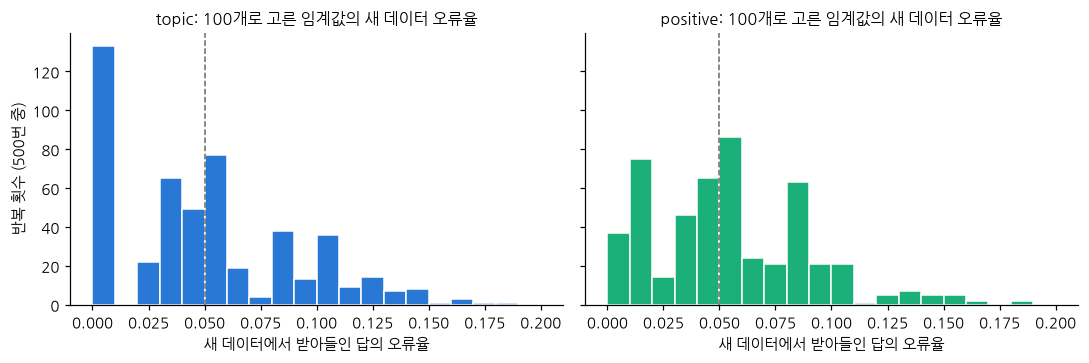

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), dpi=110, sharey=True)
for ax, t in zip(axes, ["topic", "positive"]):
    ax.hist(tr[t]["test_err"].dropna(), bins=np.arange(0, 0.21, 0.01), color=COLOR[t], edgecolor="white")
    ax.axvline(0.05, ls="--", lw=1, color="#6b6b66")
    ax.set_title(f"{t}: 100개로 고른 임계값의 새 데이터 오류율", fontsize=10.5); ax.set_xlabel("새 데이터에서 받아들인 답의 오류율")
axes[0].set_ylabel("반복 횟수 (500번 중)")
fig.tight_layout(); fig.savefig(OUT / "nb05_threshold_transfer.png", bbox_inches="tight"); plt.show()

## 5.4 위험 등급별 임계값

조회는 틀려도 다시 보면 되지만 해지와 환불은 되돌리기 어렵다. 같은 질문 하나로 의도를 고르고, 고른 행동의 위험 등급에 맞는 임계값을 넘었을 때만 실행한다. 임계값은 튜토리얼의 값(조회 0.6, 되돌릴 수 있는 변경 0.85, 파괴적·금전 0.9)에서 출발한다.

결정 규칙은 if 를 늘어놓는 대신 「조건 → 결정」 표로 쓴다. 위에서부터 처음 맞는 줄이 결정이다.

In [7]:
intent_q = {"intent": choice("고객이 지금 요청하는 행동", {
    "check_order_status": "주문·배송 상태를 확인하고 싶다", "update_address": "배송지 주소를 바꾸고 싶다",
    "cancel_subscription": "구독을 해지하고 싶다", "request_refund": "결제한 돈을 돌려받고 싶다", "other": "위 어느 것도 아니다"})}
RISK = {"check_order_status": 0.6, "update_address": 0.85, "cancel_subscription": 0.9, "request_refund": 0.9}

DECIDE = [(lambda a, p: a["choice"] not in RISK or p < 0.5, "사람에게"),
          (lambda a, p: p >= RISK[a["choice"]], "실행"),
          (lambda a, p: True, "확인 질문")]
decide = lambda a: next(d for cond, d in DECIDE if cond(a, max(a["probabilities"].values())))

messages = ["주문한 거 지금 어디쯤 왔는지 알 수 있을까요? 주문번호 A-20391이에요.", "이사해서 배송지를 서울시 마포구 월드컵로 12로 바꿔 주세요.",
            "다음 달부터 구독 해지해 주세요.", "요즘 잘 안 쓰게 되네요. 요금제를 어떻게 할지 고민 중이에요.",
            "어제 두 번 결제된 거 하나 돌려주세요.", "환불 규정이 어떻게 되나요?"]
answers = [ask({"message": m}, intent_q)["answers"]["intent"] for m in messages]
pd.DataFrame([{"메시지": m, "의도": a["choice"], "최대 확률": max(a["probabilities"].values()), "필요 임계": RISK.get(a["choice"]),
               "결정": decide(a)} for m, a in zip(messages, answers)])

,메시지,의도,최대 확률,필요 임계,결정
0,주문한 거 지금 어디쯤 왔는지 알 수 있을까요? 주문번호 A-20391이에요.,check_order_status,1.00,0.60,실행
1,이사해서 배송지를 서울시 마포구 월드컵로 12로 바꿔 주세요.,update_address,1.00,0.85,실행
2,다음 달부터 구독 해지해 주세요.,cancel_subscription,1.00,0.90,실행
3,요즘 잘 안 쓰게 되네요. 요금제를 어떻게 할지 고민 중이에요.,other,0.75,NaN,사람에게
4,어제 두 번 결제된 거 하나 돌려주세요.,request_refund,1.00,0.90,실행
5,환불 규정이 어떻게 되나요?,request_refund,0.63,0.90,확인 질문


## 5.5 신뢰도 캐스케이드

Jev 가 먼저 답하고, 확신이 임계값보다 낮은 것만 다른 쪽으로 넘긴다. 넘겨받는 쪽은 셋이다.

- **사람** — 늘 맞힌다고 보고, 한 건당 검토 비용이 든다
- **TF-IDF 기준선** — 8장의 고전 분류기. 비용은 0 이지만 약할 수 있다
- **로컬 LLM** — 사내 GPU 의 생성 모델에 같은 질문을 글로 묻는다. 토큰 비용은 없고 GPU 시간이 든다

먼저 TF-IDF 를 topic 학습 분할로 학습한다(8.3절과 같은 설정).

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

train = random.Random(0).sample(json.loads((DATA / "raw/ynat-v1.1_train.json").read_text(encoding="utf-8")), 40_000)
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3), min_df=2, max_features=200_000, sublinear_tf=True).fit([r["title"] for r in train])
clf = LogisticRegression(max_iter=4000, C=4.0).fit(vec.transform([r["title"] for r in train]), [r["label"] for r in train])
tfidf_ok = dict(zip([i["id"] for i in by["topic"]], clf.predict(vec.transform([i["state"] for i in by["topic"]])) == [i["gold"] for i in by["topic"]]))
print("TF-IDF topic 정확도:", np.mean(list(tfidf_ok.values())))

TF-IDF topic 정확도: 0.815


다음은 로컬 LLM 이다. 모델을 올리고, 제목 200개를 묶어서 묻는다. 답은 분야 이름 하나로만 쓰게 하고, 답에서 처음 나오는 분야 이름을 고른 것으로 본다. 목록에 없는 답을 쓰면 오답이다. 생성 모델은 확률을 주지 않으므로 이 폴백에는 확신이 없다.

In [9]:
from transformers import AutoModelForCausalLM, AutoTokenizer

LLM_MODEL = os.environ["LOCAL_LLM_MODEL"]
tok = AutoTokenizer.from_pretrained(LLM_MODEL, padding_side="left")
tok.pad_token = tok.pad_token or tok.eos_token
lm = AutoModelForCausalLM.from_pretrained(LLM_MODEL, dtype="auto", device_map="auto")

def chat_batch(prompts, max_new_tokens=256, batch_size=16, system=None):
    # 프롬프트 여럿을 묶어 generate 한 번에 보낸다(왼쪽 패딩). 서빙 엔진 없이 처리량을 내는 방법이다
    msgs = lambda p: [{"role": "system", "content": system}] * bool(system) + [{"role": "user", "content": p}]
    texts = [tok.apply_chat_template(msgs(p), tokenize=False, add_generation_prompt=True, enable_thinking=False) for p in prompts]
    outs = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], return_tensors="pt", padding=True).to(lm.device)
        gen = lm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
        outs += tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

chat = lambda prompt, **kw: chat_batch([prompt], **kw)[0]
print(LLM_MODEL, "|", lm.device)

menu = "\n".join(f"- {k}: {v}" for k, v in by["topic"][0]["questions"]["topic"]["criteria"].items())
prompt = lambda title: f"다음 뉴스 제목이 속한 분야를 아래 목록에서 하나만 골라 이름만 답하라.\n\n{menu}\n\n제목: {title}\n분야:"
t0 = time.perf_counter()
llm_out = chat_batch([prompt(i["state"]) for i in by["topic"]], max_new_tokens=8)
llm_pred = [next((d for d in desks if d in o), None) for o in llm_out]
llm_ok = {i["id"]: p == i["gold"] for i, p in zip(by["topic"], llm_pred)}
print(f"로컬 LLM topic 정확도 {np.mean(list(llm_ok.values())):.3f} | 목록 밖 답 {llm_pred.count(None)}건 | 200건 {time.perf_counter() - t0:.0f}초")

/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Ignoring corrupted tree cache file /data/shared/hf/hub/models--Qwen--Qwen3.5-4B/trees/851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a.json: [Errno 13] Permission denied: '/data/shared/hf/hub/models--Qwen--Qwen3.5-4B/trees/851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a.json'
Loading weights: 100%|██████████| 426/426 [00:01<00:00, 366.32it/s]


Qwen/Qwen3.5-4B | cuda:0


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


로컬 LLM topic 정확도 0.730 | 목록 밖 답 0건 | 200건 6초


임계값을 0 에서 1 까지 옮기며 넘기는 비율과 최종 정확도를 그린다.

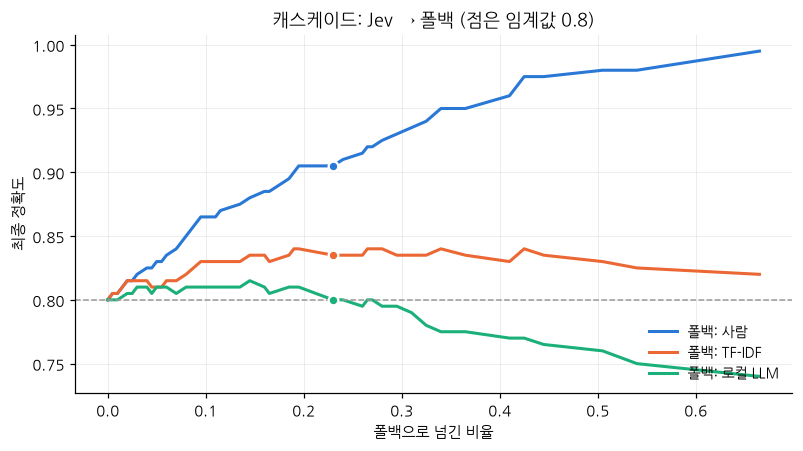

,폴백,임계 0.8 넘긴 비율,임계 0.9 넘긴 비율,임계 0.8 정확도,임계 0.9 정확도
0,사람,0.23,0.31,0.905,0.935
1,TF-IDF,0.23,0.31,0.835,0.835
2,로컬 LLM,0.23,0.31,0.800,0.790


In [10]:
J = {r["id"]: r for r in jev["topic"]}
fallbacks = {"사람": {i: True for i in J}, "TF-IDF": tfidf_ok, "로컬 LLM": llm_ok}

def cascade(t, fb):
    sent = {i for i, r in J.items() if r["conf"] < t}
    return len(sent) / len(J), np.mean([fb[i] if i in sent else J[i]["correct"] for i in J])

fig, ax = plt.subplots(figsize=(7.4, 4.2), dpi=110)
for (name, fb), color in zip(fallbacks.items(), ["#2a78d6", "#eb6834", "#1baf7a"]):
    ax.plot(*zip(*[cascade(t, fb) for t in np.linspace(0, 1, 101)]), lw=2, color=color, label=f"폴백: {name}")
    ax.scatter(*cascade(0.8, fb), s=40, color=color, edgecolor="white", linewidth=1.5, zorder=3)
ax.axhline(np.mean([r["correct"] for r in J.values()]), ls="--", lw=1, color="#9a9a96")
ax.set_xlabel("폴백으로 넘긴 비율"); ax.set_ylabel("최종 정확도"); ax.set_title("캐스케이드: Jev → 폴백 (점은 임계값 0.8)", fontsize=12)
ax.grid(alpha=0.25, lw=0.6); ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "nb05_cascade.png", bbox_inches="tight"); plt.show()

pd.DataFrame([{"폴백": n, **{f"임계 {t} 넘긴 비율": cascade(t, fb)[0] for t in (0.8, 0.9)},
               **{f"임계 {t} 정확도": cascade(t, fb)[1] for t in (0.8, 0.9)}} for n, fb in fallbacks.items()])

In [11]:
# 5.6 은 로컬 LLM 을 쓰지 않으므로 GPU 메모리를 비운다
del lm
import torch; torch.cuda.empty_cache()

## 5.6 투기적 팬아웃

다음 질문이 앞 답에 따라 갈리는 의사결정 나무가 있다고 하자. 앞 답을 받은 뒤 다시 묻는 대신, 쓸 수도 있는 질문을 처음부터 전부 묻고 필요한 것만 읽는다. 쓰지 않은 질문의 값은 입력 토큰 몇 개다. 라우팅 규칙은 5.4절처럼 「조건 → 큐」 표로 둔다.

In [12]:
state = {"channel": "앱 문의", "message": "CSV 내보내기를 누르면 앱이 꺼지고 파일이 깨져요. 이번 주만 세 번째예요. 안 고쳐지면 해지하고 환불 받을 거예요."}
Q = {"department": choice("이 문의를 처리할 팀", {"billing": "결제, 환불, 청구 오류", "technical": "앱 오류, 로그인, 연동 문제",
                                             "account": "가입, 해지, 요금제 변경", "general": "그 밖의 문의"}),
     "bug_severity": score("오류가 업무에 주는 피해", ["불편한 정도", "작업이 막힌다", "데이터가 손상된다"]),
     "churn_risk": noul("고객이 해지를 언급하거나 해지할 뜻을 보인다"),
     "wants_refund": noul("고객이 환불을 요구한다"),
     "repeat_issue": noul("같은 문제가 여러 번 반복됐다고 말한다")}

ROUTES = [(lambda a: a["department"]["choice"] == "technical" and (a["bug_severity"]["score"] >= 1.5 or a["repeat_issue"]["noul"] > 0.5)
                     and a["churn_risk"]["noul"] > 0.5, "엔지니어 긴급 큐 + 리텐션팀 통보"),
          (lambda a: a["department"]["choice"] == "technical" and (a["bug_severity"]["score"] >= 1.5 or a["repeat_issue"]["noul"] > 0.5), "엔지니어 긴급 큐"),
          (lambda a: a["department"]["choice"] == "technical", "기술지원 일반 큐"),
          (lambda a: a["department"]["choice"] == "billing" and a["wants_refund"]["noul"] > 0.5, "환불 처리 큐"),
          (lambda a: True, "일반 문의 큐")]
route = lambda a: next(q for cond, q in ROUTES if cond(a))

one, fan = ask(state, {"department": Q["department"]}), ask(state, Q)
print(f"질문 1개: 입력 {one['usage']['input_tokens']} 토큰, {one['_latency_s']:.2f}초")
print(f"질문 5개: 입력 {fan['usage']['input_tokens']} 토큰, {fan['_latency_s']:.2f}초")
print("라우팅  :", route(fan["answers"]))
print(json.dumps(fan["answers"], ensure_ascii=False, indent=1)[:900])

질문 1개: 입력 422 토큰, 0.16초
질문 5개: 입력 540 토큰, 0.16초
라우팅  : 엔지니어 긴급 큐 + 리텐션팀 통보
{
 "department": {
  "type": "choice",
  "choice": "technical",
  "confidence": 1.0,
  "probabilities": {
   "billing": 0.0,
   "technical": 1.0,
   "account": 0.0,
   "general": 0.0
  }
 },
 "bug_severity": {
  "type": "score",
  "score": 1.99,
  "confidence": 1.0,
  "legend": {
   "0": "불편한 정도",
   "1": "작업이 막힌다",
   "2": "데이터가 손상된다"
  },
  "probabilities": {
   "0": 0.0,
   "1": 0.0,
   "2": 1.0
  }
 },
 "churn_risk": {
  "type": "noul",
  "noul": 0.97
 },
 "wants_refund": {
  "type": "noul",
  "noul": 0.8
 },
 "repeat_issue": {
  "type": "noul",
  "noul": 0.97
 }
}


## 정리

이 노트북이 잰 것이다. 결과 해석은 5장 본문에서 한다.

- 5.1 라우팅 혼동 행렬과 확신이 높았던 오답
- 5.2 세 구간 게이트의 구간별 비율과 정확도 (최대 확률 기준과 confidence 필드 기준)
- 5.3 100개로 고른 임계값이 나머지 100개에서 낸 처리율·오류율의 분포
- 5.4 행동 위험 등급별 임계값을 건 결정
- 5.5 폴백(사람·TF-IDF·로컬 LLM)별 캐스케이드 곡선과 로컬 LLM 의 정확도·시간
- 5.6 질문 1개와 5개의 입력 토큰·지연, 한 번의 요청으로 내린 라우팅